In [16]:
import pandas as pd
import sqlite3
from pandas.plotting import scatter_matrix

In [17]:
conn = sqlite3.connect("../data/checking-logs.sqlite")

In [18]:
df = pd.io.sql.read_sql(
    """--sql
    WITH commits_cte AS (
    SELECT t.uid, AVG((strftime ('%s', t.first_commit_ts) - d.deadlines) / 3600) AS avg_diff
    FROM test AS t JOIN deadlines AS d 
    ON t.labname = d.labs
    WHERE t.labname != 'project1'
    GROUP BY t.uid
    ),
    views_cte AS (
    SELECT uid, COUNT(datetime) AS pageviews
    FROM pageviews 
    GROUP BY uid),

    joinedCTE AS (
    SELECT c.uid, c.avg_diff, IFNULL(v.pageviews, 0) AS pageviews 
    FROM commits_cte AS c 
    LEFT JOIN views_cte AS v
    ON c.uid=v.uid)
    
    SELECT joinedCTE.uid AS uid,
    avg_diff, pageviews, num_commits
    FROM joinedCTE
    LEFT JOIN 
    (SELECT uid, count(*) AS num_commits
    FROM checker 
    where labname != 'project1' and uid not like 'admin%' GROUP BY uid) as comms_num
    ON joinedCTE.uid = comms_num.uid
    """,
    conn,
)
df

,uid,avg_diff,pageviews,num_commits
0,user_1,-64.400000,28,62
1,user_10,-74.800000,89,20
2,user_14,-159.000000,143,61
3,user_17,-61.600000,47,51
4,user_18,-5.666667,3,5
5,user_19,-98.750000,16,118
6,user_21,-95.500000,10,65
7,user_25,-92.600000,179,79
8,user_28,-86.400000,149,60
9,user_3,-105.400000,317,18


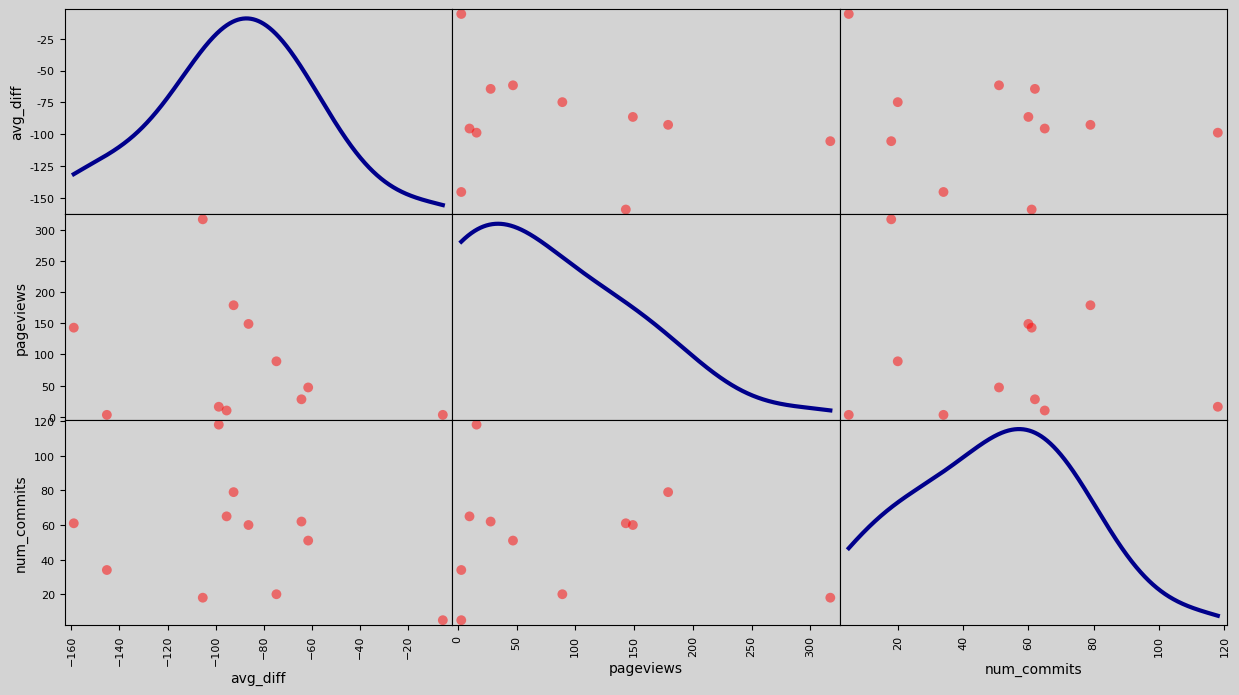

In [19]:
graphs = scatter_matrix(
    df,
    s=200,
    color="red",
    alpha=0.5,
    figsize=(15, 8),
    diagonal="kde",
)
graphs[0][0].figure.set_facecolor("lightgrey")

for ax in graphs.flat:
    ax.set_facecolor("lightgrey")

for i in range(len(graphs)):
    ax_diag = graphs[i][i]
    ax_diag.lines[0].set_color("darkblue")
    ax_diag.lines[0].set_linewidth(3)


In [20]:
# cols = ["avg_diff", "pageviews", "num_commits"]
# corr_matrix = df[cols].corr(method="spearman")
# print(corr_matrix.round(3))

In [21]:
df.describe()

,avg_diff,pageviews,num_commits
count,11.000000,11.000000,11.000000
mean,-89.942424,89.454545,52.090909
std,41.209574,99.219316,31.957642
min,-159.000000,3.000000,5.000000
25%,-102.075000,13.000000,27.000000
50%,-92.600000,47.000000,60.000000
75%,-69.600000,146.000000,63.500000
max,-5.666667,317.000000,118.000000


In [22]:
conn.close()

### Можно ли сказать, что если у пользователя мало просмотров ленты, то у него, вероятно, мало коммитов?

Нет. Точки распределены хаотично, корреляция отсутствует.

### Можно ли сказать, что если у пользователя мало просмотров ленты, то у него, вероятно, малая средняя разница между первым коммитом и дедлайном лабораторной?

Нет. Аналогично.

### Можно ли сказать, что много пользователей с малым числом коммитов и немного — с большим числом коммитов?

Да. Распределение скошено вправо: пик плотности приходится на малые значения, а хвост тянется к большим.

### Можно ли сказать, что много пользователей с малой средней разницей и немного — с большой средней разницей?

Нет. Распределение симметрично (колоколообразное), значения равномерно сосредоточены вокруг среднего.